In [2]:
import torch
from diffusers import StableDiffusionPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype,
    safety_checker=None 
)

pipe = pipe.to(device)

pipe.enable_attention_slicing()

print(f"✅ Pipeline loaded on {device} ({dtype})")

/home/sayak/Documents/RetailMind AI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.
/home/sayak/Documents/RetailMind AI/.venv/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please us

✅ Pipeline loaded on cuda (torch.float16)


In [7]:
def build_product_prompt(category: str, style: str, setting: str) -> str:
    return (
        f"Commercial product photography of {category}, {style} aesthetic, "
        f"placed in {setting}, soft studio lighting, sharp focus, high detail, 4k"
    )

prompt_library = {
    "Apparel": {
        "category": "tailored organic cotton casual jacket on an invisible mannequin",
        "style": "clean editorial e-commerce fashion",
        "setting": "a soft light-grey studio backdrop with diffused natural lighting",
        "seed": 42
    },
    "Accessories": {
        "category": "minimalist brushed-steel chronograph wristwatch with leather strap",
        "style": "luxury modern commercial",
        "setting": "a matte slate surface with subtle warm rim lighting",
        "seed": 108
    },
    "Footwear": {
        "category": "sleek white and navy low-top leather sneakers",
        "style": "crisp contemporary streetwear",
        "setting": "a minimalist concrete pedestal with soft directional shadows",
        "seed": 215
    },
    "Personal Care": {
        "category": "frosted amber glass botanical serum dropper bottle",
        "style": "clean spa aesthetic skincare",
        "setting": "a sunlit travertine stone tray beside fresh eucalyptus leaves",
        "seed": 309
    },
    "Free Items": {
        "category": "branded canvas tote bag and enamel lapel pin gift bundle",
        "style": "bright friendly promotional flat-lay",
        "setting": "a clean pastel cream surface with soft overhead studio light",
        "seed": 412
    },
    "Sporting Goods": {
        "category": "matte black insulated stainless steel sports water bottle and grip dumbbells",
        "style": "dynamic athletic product photography",
        "setting": "a dark textured gym floor with crisp high-contrast lighting",
        "seed": 527
    }
}

NEGATIVE_PROMPT = (
    "blurry, low quality, distorted, watermark, text, logo, cluttered background, "
    "oversaturated, deformed, bad proportions"
)

In [8]:
def generate_marketing_asset(item_key: str, steps: int = 15, size: int = 384):
    meta = prompt_library[item_key]
    prompt = build_product_prompt(meta["category"], meta["style"], meta["setting"])
    
    generator = torch.Generator(device=device).manual_seed(meta["seed"])
    
    print(f"Generating '{item_key}' with prompt:\n> {prompt}\n")
    
    image = pipe(
        prompt=prompt,
        negative_prompt=NEGATIVE_PROMPT,
        num_inference_steps=steps,   
        guidance_scale=7.5,          
        height=size,                 
        width=size,
        generator=generator
    ).images[0]
    
    return image

Generating 'Apparel' with prompt:
> Commercial product photography of tailored organic cotton casual jacket on an invisible mannequin, clean editorial e-commerce fashion aesthetic, placed in a soft light-grey studio backdrop with diffused natural lighting, soft studio lighting, sharp focus, high detail, 4k



  0%|          | 0/15 [00:00<?, ?it/s]

100%|██████████| 15/15 [00:12<00:00,  1.16it/s]


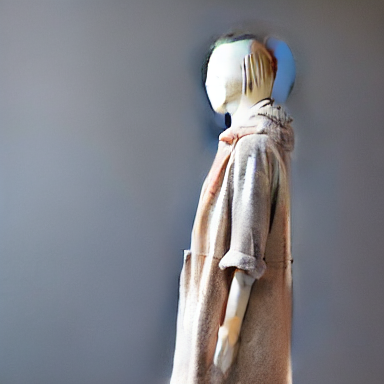

In [10]:
test_image = generate_marketing_asset("Apparel")
display(test_image)

Generating 'Footwear' with prompt:
> Commercial product photography of sleek white and navy low-top leather sneakers, crisp contemporary streetwear aesthetic, placed in a minimalist concrete pedestal with soft directional shadows, soft studio lighting, sharp focus, high detail, 4k



100%|██████████| 15/15 [00:12<00:00,  1.16it/s]


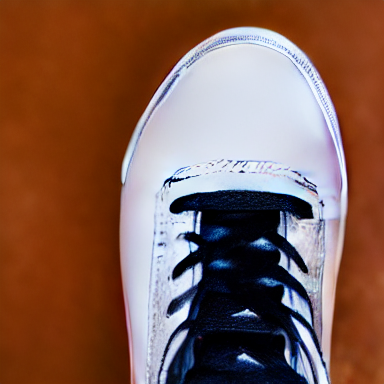

In [11]:
test_image = generate_marketing_asset("Footwear")
display(test_image)